# Video object segmentation: propagating SAM 3 and SAM 2.1 masks through DAVIS 2017

A mobile robot rarely sees an object once: it has to keep a mask on it while the camera
and the object move. **Semi-supervised video object segmentation (VOS)** gives the target
on the first frame (a mask, a box or a click) and asks for its mask in every later frame.
SAM 2 turned the Segment Anything idea into a streaming video model with a **memory
bank**; SAM 3 keeps that tracker and adds **concept tracking** from a text prompt.

**What you will learn**

1. How the streaming memory architecture of SAM 2 / SAM 3 propagates a prompt through
   time, and why it can recover from occlusion.
2. The DAVIS metrics: region similarity $\mathcal{J}$ (IoU), boundary accuracy
   $\mathcal{F}$, their mean, recall and decay, and how to compute them.
3. How prompt strength (full mask vs box vs one click) on frame 0 affects the whole clip.
4. Text-prompted video segmentation with SAM 3 (`Sam3VideoModel`): find *and* track every
   instance of "dog" without a single click.

**Data**: two sequences of the DAVIS 2017 **validation** split at 480p (downloaded by
`make data-05_segmentation` via HTTP range requests, about 25 MB instead of the 833 MB
archive): `car-roundabout` (1 object, 75 frames) and `dogs-jump` (a person and two dogs,
66 frames, fast motion and occlusion). Hardware: RTX 5060 Laptop GPU (8 GB), bfloat16.

## Setup

Imports, seeding, device and plotting style. `segkit` provides the DAVIS loader, the
J/F metrics and thin wrappers around the `transformers` video APIs.

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# segkit (projects/05_segmentation/scripts/segkit.py) holds the data loaders, metrics and
# model adapters shared by all notebooks of this project, the benchmark script and the solutions.
# Photo grids are displayed with sk.show_jpeg (JPEG is ~5-10x smaller than PNG for photos);
# charts stay PNG via plt.show().
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from cvlab import device as cvdevice
from cvlab import viz
from cvlab.device import track_vram
from cvlab.io import project_dir, repo_root

PROJECT = "05_segmentation"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import segkit as sk  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()
warnings.filterwarnings("ignore")  # silence library warnings in the rendered notebook
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
RESULTS = sk.results_dir()
print("results dir:", RESULTS.relative_to(repo_root()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


results dir: projects/05_segmentation/results


## Data: DAVIS 2017 sequences

DAVIS annotations are **palette PNGs**: the pixel value is the object id (0 = background,
$1..K$ = objects), so they must be read as indices (PIL), not converted to RGB colours
(OpenCV would do that). Frame 0's label map is the prompt source; all later frames are
the evaluation targets.

car-roundabout: 75 frames of 854x480 px, objects [1]
dogs-jump: 66 frames of 854x480 px, objects [1, 2, 3]


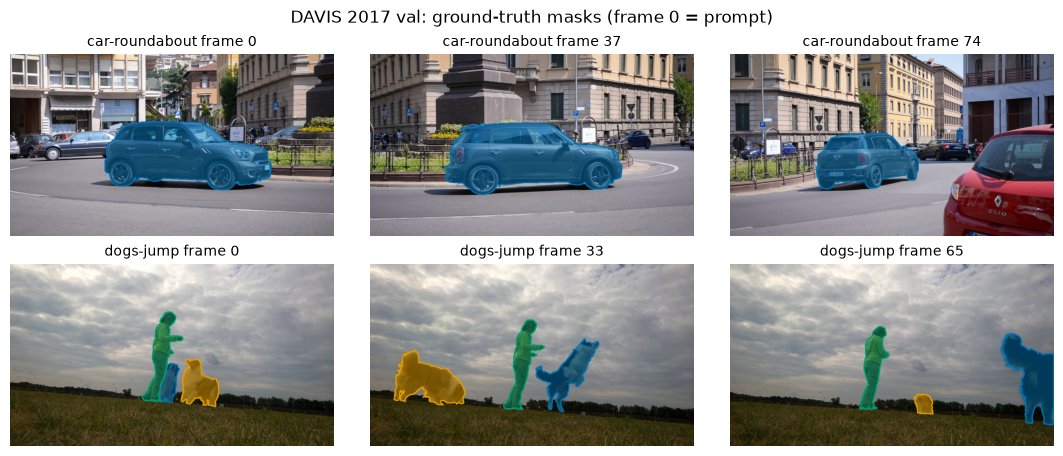

In [2]:
# --- Load the two DAVIS 2017 val sequences (frames + per-frame object-id maps) ---
# frames: list of 480 x 854 x 3 uint8 RGB; labels: T x 480 x 854 uint8 object ids.
SEQS = ["car-roundabout", "dogs-jump"]
davis = {seq: sk.load_davis(seq) for seq in SEQS}
panels, titles = [], []
for seq, (frames, labels) in davis.items():
    ids = sk.object_ids(labels)
    T = len(frames)
    print(f"{seq}: {T} frames of {frames[0].shape[1]}x{frames[0].shape[0]} px, objects {ids}")
    for t in (0, T // 2, T - 1):
        panels.append(viz.overlay_masks(frames[t], np.stack([labels[t] == i for i in ids])))
        titles.append(f"{seq} frame {t}")
fig = viz.show_images(panels, titles=titles, ncols=3, size=3.6,
                      suptitle="DAVIS 2017 val: ground-truth masks (frame 0 = prompt)")
sk.show_jpeg(fig)  # photos: JPEG keeps the notebook small

## The metrics: $\mathcal{J}$ and $\mathcal{F}$

For a predicted mask $P$ and ground truth $G$ of one object in one frame:

* **Region similarity** $\mathcal{J} = \dfrac{|P \cap G|}{|P \cup G|}$ (IoU, 1 if both are empty).
* **Boundary accuracy** $\mathcal{F} = \dfrac{2 P_c R_c}{P_c + R_c}$, where the contour
  precision $P_c$ is the fraction of predicted boundary pixels within a tolerance of the GT
  boundary and recall $R_c$ the converse. The tolerance is a disk of radius
  $\lceil 0.008 \cdot \text{diagonal} \rceil$ = 8 px at $854 \times 480$.

Per object, DAVIS summarises each per-frame series $x_t$ by its **mean**, its **recall**
(fraction of frames with $x_t > 0.5$) and its **decay** (mean of the first quarter of
frames minus mean of the last quarter: how much the tracker drifts). The headline number
is $\mathcal{J}\&\mathcal{F} = (\bar{\mathcal{J}} + \bar{\mathcal{F}}) / 2$. As in the
official evaluation, the prompted first frame and the last frame are excluded. The
implementation (`segkit.f_measure`) is unit-tested in `tests/test_p05_segkit.py`; below is
a sanity check of how strict the two metrics are.

In [3]:
# --- Sanity check: how J and F react to shifting a GT mask by a few pixels ---
# A shift inside the 8 px tolerance keeps F at 1 while J already drops.
gt = davis["car-roundabout"][1][10] == 1
print(f"boundary tolerance: {sk.boundary_radius(gt.shape)} px")
for dx in (0, 2, 4, 8, 16):
    shifted = np.roll(gt, dx, axis=1)
    print(f"shift {dx:2d} px -> J = {sk.j_measure(shifted, gt):.3f}, F = {sk.f_measure(shifted, gt):.3f}")

boundary tolerance: 8 px
shift  0 px -> J = 1.000, F = 1.000
shift  2 px -> J = 0.984, F = 1.000
shift  4 px -> J = 0.969, F = 1.000
shift  8 px -> J = 0.942, F = 1.000
shift 16 px -> J = 0.892, F = 0.709


## How SAM 2 / SAM 3 propagate a prompt

Each frame goes through the image encoder once. Instead of re-prompting every frame, the
model keeps a **memory bank**: for the prompted frame(s) and the most recent frames
(6 in SAM 2) it stores a *memory encoding* (image features fused with the predicted mask)
plus an *object pointer* token. **Memory attention** cross-attends the current frame's
features to that bank before the mask decoder runs, so the decoder "knows" which object
to segment. An **occlusion head** predicts whether the object is visible at all; when it
reappears the prompted-frame memory lets the tracker pick it up again.

SAM 3's tracker (`Sam3TrackerVideoModel`) has the same design on top of SAM 3's
Perception Encoder. Both run here through the same `segkit.VideoTracker` wrapper; frames
are pre-processed and stored on the CPU, only the active frame is moved to the GPU.

We start with the standard DAVIS semi-supervised protocol: the **full GT mask** of every
object on frame 0.

In [4]:
# --- Track all objects of every sequence with both models (frame-0 GT-mask prompts) ---
# Each model is loaded once; per run we record J/F per object and frame, speed and VRAM.
VIDEO_MODELS = [sk.SAM3_ID, sk.SAM2_IDS["small"]]
PROMPTS = ["mask", "box", "click"]
preds, per_frame, rows = {}, {}, []
for mid in VIDEO_MODELS:
    torch.cuda.empty_cache()
    with track_vram() as mem:
        tracker = sk.VideoTracker(mid, device=str(device))
        for prompt in PROMPTS:
            for seq, (frames, labels) in davis.items():
                pred, info = tracker.track(frames, labels[0], prompt=prompt)
                per_obj = sk.evaluate_vos(pred, labels)
                stats = sk.summarize_vos(per_obj)
                preds[(tracker.label, prompt, seq)] = pred
                per_frame[(tracker.label, prompt, seq)] = per_obj
                rows.append({"model": tracker.label, "prompt": prompt, "sequence": seq,
                             **{k: round(v, 4) for k, v in stats.items()},
                             "ms/frame": round(info["ms_per_frame"], 1)})
    for r in rows:
        if r["model"] == tracker.label:
            r["peak VRAM (MiB)"] = round(mem.peak_mb, 0)
    print(f"{tracker.label}: {tracker.n_params_m:.0f} M params, peak VRAM {mem.peak_mb:.0f} MiB")
    del tracker
vos = pd.DataFrame(rows)
vos[vos.prompt == "mask"][["model", "sequence", "J_mean", "F_mean", "JF_mean", "J_decay", "ms/frame"]]

SAM 3: 466 M params, peak VRAM 1943 MiB


SAM 2.1-S: 46 M params, peak VRAM 1014 MiB


,model,sequence,J_mean,F_mean,JF_mean,J_decay,ms/frame
0,SAM 3,car-roundabout,0.9891,0.9766,0.9829,0.0015,415.1
1,SAM 3,dogs-jump,0.9453,0.9922,0.9688,-0.0416,543.8
6,SAM 2.1-S,car-roundabout,0.9878,0.9698,0.9788,0.0016,81.3
7,SAM 2.1-S,dogs-jump,0.9419,0.9920,0.9670,-0.0403,168.4


Per-frame $\mathcal{J}$ shows *when* tracking fails. In `dogs-jump` the two dogs cross
each other and the person, the hardest moments for any tracker that must keep identities
apart.

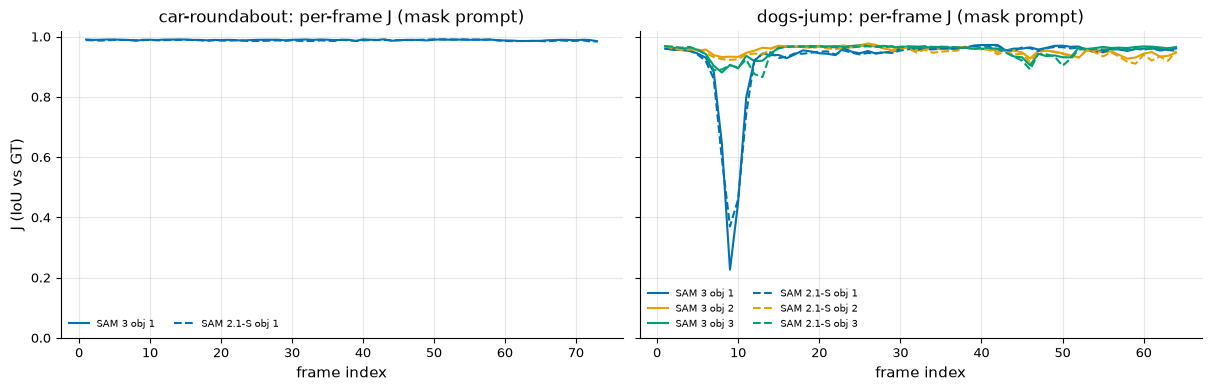

In [5]:
# --- Per-frame J of every object (mask prompt) for both models ---
# Frame index on x (frame 0 is the prompt and is excluded, as is the last frame).
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, seq in zip(axes, SEQS):
    for mi, mid in enumerate(VIDEO_MODELS):
        label = sk.model_label(mid)
        for oi, (oid, d) in enumerate(per_frame[(label, "mask", seq)].items()):
            ax.plot(np.arange(1, len(d["J"]) + 1), d["J"], ["-", "--"][mi],
                    color=viz.color(oi, unit=True), label=f"{label} obj {oid}")
    ax.set_title(f"{seq}: per-frame J (mask prompt)")
    ax.set_xlabel("frame index")
    ax.set_ylim(0, 1.02)
    ax.legend(ncols=2, fontsize=7, loc="lower left")
axes[0].set_ylabel("J (IoU vs GT)")
viz.savefig(fig, PROJECT, "davis_j_per_frame")
plt.show()

Let us look at the frame where SAM 2.1-S is worst on `dogs-jump` and compare both models
there (colours = object ids, same palette as the GT).

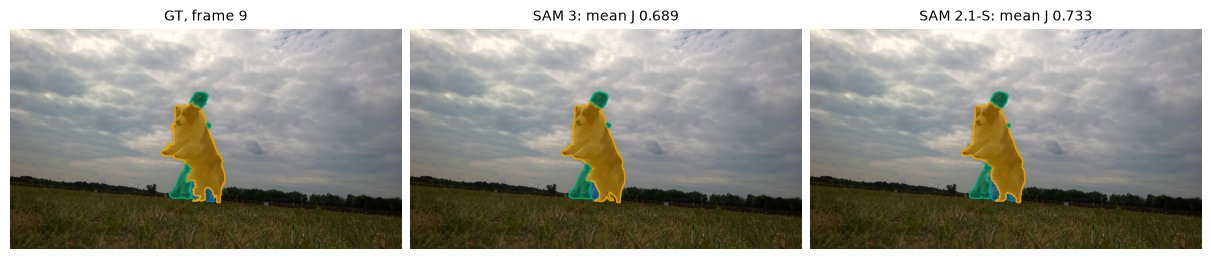

In [6]:
# --- Qualitative check at the hardest frame (lowest mean J of SAM 2.1-S, mask prompt) ---
seq = "dogs-jump"
frames, labels = davis[seq]
ids = sk.object_ids(labels)
j_mean = np.mean([d["J"] for d in per_frame[("SAM 2.1-S", "mask", seq)].values()], axis=0)
t = int(np.argmin(j_mean)) + 1  # +1: frame 0 is excluded from the per-frame arrays
panels = [viz.overlay_masks(frames[t], np.stack([labels[t] == i for i in ids]))]
titles = [f"GT, frame {t}"]
for mid in VIDEO_MODELS:
    label = sk.model_label(mid)
    p = preds[(label, "mask", seq)][t]
    jt = np.mean([sk.j_measure(p == i, labels[t] == i) for i in ids])
    panels.append(viz.overlay_masks(frames[t], np.stack([p == i for i in ids])))
    titles.append(f"{label}: mean J {jt:.3f}")
fig = viz.show_images(panels, titles=titles, ncols=3, size=4.0)
sk.show_jpeg(fig)

## Concept tracking from text with SAM 3

`Sam3VideoModel` combines SAM 3's **detector** (text -> all matching instances, run on
every frame) with the tracker: new detections that do not match an existing masklet start
new tracks, matched ones re-condition the tracker, and unconfirmed tracks are removed
after a short "hot-start" delay. No click is needed - the prompt is just a noun phrase.

To score it we match predicted tracks to GT objects with the Hungarian algorithm on mean
per-frame IoU (`segkit.match_tracks_to_gt`) and compute J/F of the matched tracks. Extra
tracks (e.g. another car in the background) are not penalised by J/F, so we also report
how many tracks were created.

One honest caveat: `transformers` runs SAM 3's video post-processing (NMS between
detections, hole filling, removal of small "sprinkle" components) only when the optional
`kernels` package is installed, which downloads compiled CUDA kernels from the Hugging Face
Hub at runtime. This repository does not install it, so those steps are skipped here and
the masks are the raw tracker outputs.

In [7]:
# --- Text-prompted video segmentation with Sam3VideoModel ---
# One run per (sequence, phrase); tracks are matched to the GT objects of that class.
TEXT_QUERIES = {"car-roundabout": {"car": [1]}, "dogs-jump": {"person": [3], "dog": [1, 2]}}  # DAVIS ids: 3 = person
torch.cuda.empty_cache()
text_rows, text_tracks = [], {}
with track_vram() as mem:
    tvt = sk.TextVideoTracker(device=str(device))
    for seq, queries in TEXT_QUERIES.items():
        frames, labels = davis[seq]
        for phrase, gt_ids in queries.items():
            tracks, info = tvt.track(frames, phrase)
            text_tracks[(seq, phrase)] = tracks
            sub = np.where(np.isin(labels, gt_ids), labels, 0)  # GT restricted to this class
            match = sk.match_tracks_to_gt(tracks, sub)
            for gid, tid in match.items():
                pred = np.zeros_like(labels) if tid is None else (tracks[tid] * gid).astype(np.uint8)
                st = sk.summarize_vos(sk.evaluate_vos(pred, np.where(labels == gid, gid, 0)))
                text_rows.append({"sequence": seq, "phrase": phrase, "GT object": gid,
                                  "track": tid, "tracks created": len(tracks),
                                  **{k: round(st[k], 4) for k in ("J_mean", "F_mean", "JF_mean")},
                                  "ms/frame": round(info["ms_per_frame"], 1)})
print(f"Sam3VideoModel: {tvt.n_params_m:.0f} M params, peak VRAM {mem.peak_mb:.0f} MiB")
text_peak_mib = mem.peak_mb
del tvt
text_df = pd.DataFrame(text_rows)
text_df

Sam3VideoModel: 860 M params, peak VRAM 6325 MiB


,sequence,phrase,GT object,track,tracks created,J_mean,F_mean,JF_mean,ms/frame
0,car-roundabout,car,1,6,19,0.9817,0.9614,0.9715,1588.7
1,dogs-jump,person,3,0,1,0.9532,0.9903,0.9717,469.5
2,dogs-jump,dog,1,1,2,0.9252,0.9867,0.9560,545.4
3,dogs-jump,dog,2,0,2,0.9549,0.9964,0.9757,545.4


A few frames of the text-prompted result on `dogs-jump` (phrases "person" and "dog";
each track gets its own colour). The same frames are written to an animated GIF for the
project README (`assets/05_segmentation/davis_sam3_text.gif`), which is not embedded in the
notebook.

GIF: assets/05_segmentation/davis_sam3_text.gif (860 KiB)


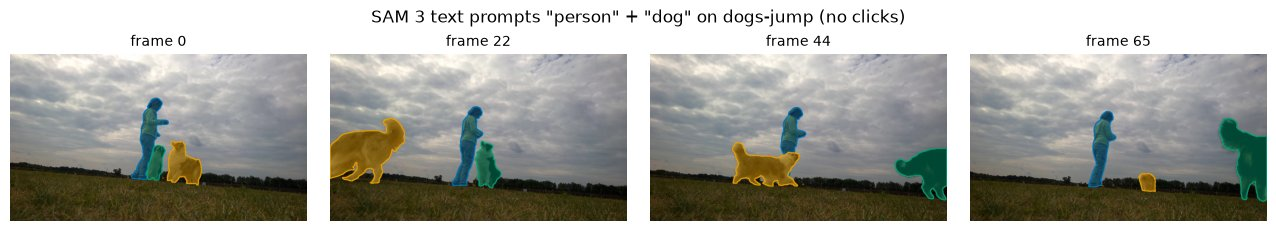

In [8]:
# --- Visualise text-prompted tracks and save a GIF for the README ---
seq = "dogs-jump"
frames, labels = davis[seq]
all_tracks = [m for phrase in ("person", "dog") for m in text_tracks[(seq, phrase)].values()]
overlays = [viz.overlay_masks(frames[t], np.stack([m[t] for m in all_tracks]), alpha=0.45)
            if all_tracks else frames[t] for t in range(len(frames))]
from cvlab.io import assets_dir

gif = viz.save_gif(overlays[::2], assets_dir(PROJECT) / "davis_sam3_text.gif", fps=6, max_side=400)
print(f"GIF: {gif.relative_to(repo_root())} ({gif.stat().st_size / 1024:.0f} KiB)")
T = len(frames)
fig = viz.show_images([overlays[t] for t in (0, T // 3, 2 * T // 3, T - 1)],
                      titles=[f"frame {t}" for t in (0, T // 3, 2 * T // 3, T - 1)], ncols=4, size=3.2,
                      suptitle='SAM 3 text prompts "person" + "dog" on dogs-jump (no clicks)')
viz.savefig(fig, PROJECT, "davis_sam3_text_frames")
sk.show_jpeg(fig)
# small thumbnail (~400 px wide) for the project table of the root README; not displayed here
fig_t, ax_t = plt.subplots(figsize=(3.4, 1.95))
ax_t.imshow(overlays[T // 2])
ax_t.axis("off")
viz.savefig(fig_t, PROJECT, "thumb")
plt.close(fig_t)

## Results

$\mathcal{J}\&\mathcal{F}$ per model, prompt type and sequence (mask = full GT mask on
frame 0; box = tight GT box; click = one positive click at each object's interior
point), the text-prompted SAM 3 runs, and speed/memory. All numbers were measured in this
notebook on two sequences only, so they illustrate behaviour rather than rank the models
(the official DAVIS 2017 val set has 30 sequences).

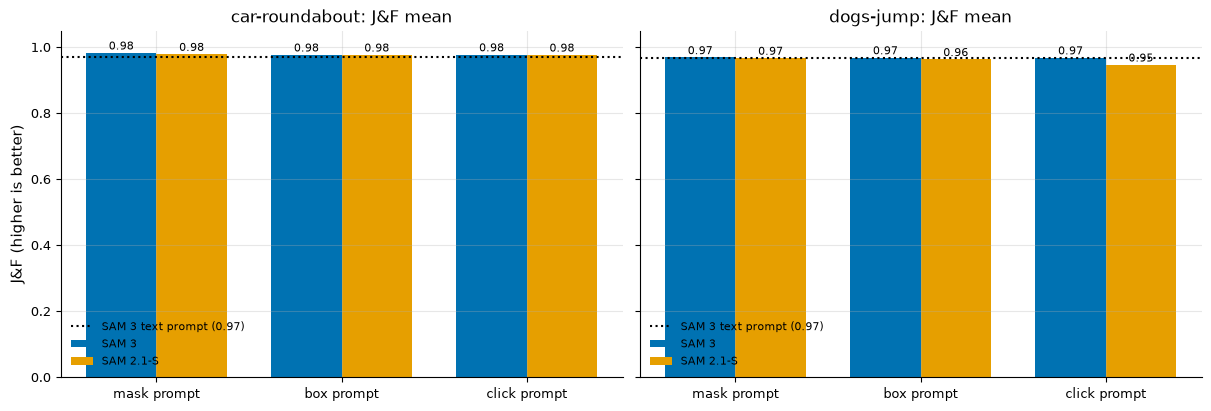

In [9]:
# --- Figure: J&F per prompt type, model and sequence (+ text-prompted SAM 3) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), sharey=True)
width = 0.38
for ax, seq in zip(axes, SEQS):
    for mi, mid in enumerate(VIDEO_MODELS):
        label = sk.model_label(mid)
        sub = vos[(vos.model == label) & (vos.sequence == seq)].set_index("prompt").loc[PROMPTS]
        xs = np.arange(len(PROMPTS)) + (mi - 0.5) * width
        ax.bar(xs, sub["JF_mean"], width, label=label, color=viz.color(mi, unit=True))
        for x, v in zip(xs, sub["JF_mean"]):
            ax.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    txt = text_df[text_df.sequence == seq]["JF_mean"].mean()
    ax.axhline(txt, color="k", ls=":", label=f"SAM 3 text prompt ({txt:.2f})")
    ax.set_xticks(range(len(PROMPTS)), [f"{p} prompt" for p in PROMPTS])
    ax.set_title(f"{seq}: J&F mean")
    ax.set_ylim(0, 1.05)
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("J&F (higher is better)")
viz.savefig(fig, PROJECT, "davis_jf_by_prompt")
plt.show()

Full summary table (J/F mean, recall and decay averaged over the objects of each
sequence; ms/frame includes pre-processing transfer, the encoder, memory attention and
upsampling the masks to 854x480).

In [10]:
# --- Summary table (all runs of this notebook) + save as a small CSV for the README ---
cols = ["model", "prompt", "sequence", "J_mean", "F_mean", "JF_mean", "J_recall", "J_decay",
        "ms/frame", "peak VRAM (MiB)"]
summary = vos[cols].copy()
for seq in SEQS:
    sub = text_df[text_df.sequence == seq]
    summary.loc[len(summary)] = ["SAM 3 (Sam3VideoModel)", "text", seq, sub.J_mean.mean().round(4),
                                 sub.F_mean.mean().round(4), sub.JF_mean.mean().round(4),
                                 np.nan, np.nan, sub["ms/frame"].mean().round(1),
                                 round(text_peak_mib, 0)]
summary.to_csv(RESULTS / "nb03_davis_summary.csv", index=False)
summary

,model,prompt,sequence,J_mean,F_mean,JF_mean,J_recall,J_decay,ms/frame,peak VRAM (MiB)
0,SAM 3,mask,car-roundabout,0.9891,0.9766,0.9829,1.0000,0.0015,415.1,1943.0
1,SAM 3,mask,dogs-jump,0.9453,0.9922,0.9688,0.9896,-0.0416,543.8,1943.0
2,SAM 3,box,car-roundabout,0.9861,0.9677,0.9769,1.0000,-0.0018,411.8,1943.0
3,SAM 3,box,dogs-jump,0.9451,0.9920,0.9685,0.9896,-0.0421,544.4,1943.0
4,SAM 3,click,car-roundabout,0.9868,0.9681,0.9774,1.0000,-0.0011,411.8,1943.0
5,SAM 3,click,dogs-jump,0.9440,0.9923,0.9682,0.9896,-0.0435,545.1,1943.0
6,SAM 2.1-S,mask,car-roundabout,0.9878,0.9698,0.9788,1.0000,0.0016,81.3,1014.0
7,SAM 2.1-S,mask,dogs-jump,0.9419,0.9920,0.9670,0.9896,-0.0403,168.4,1014.0
8,SAM 2.1-S,box,car-roundabout,0.9851,0.9685,0.9768,1.0000,0.0012,81.2,1014.0
9,SAM 2.1-S,box,dogs-jump,0.9364,0.9896,0.9630,0.9896,-0.0468,168.5,1014.0


### Takeaways

* **With a full-mask prompt both trackers are near the ceiling on these clips.** J&F is
  0.9829 / 0.9688 for SAM 3 and 0.9788 / 0.9670 for SAM 2.1-S on car-roundabout /
  dogs-jump. Differences of a few thousandths cannot be resolved with two sequences.
* **A weaker first-frame prompt hurts the small model more.** With one click per object
  on dogs-jump, SAM 2.1-S drops to J&F 0.9465 (J decay -0.0761) while SAM 3 stays at
  0.9682; with a box the values are 0.9630 vs 0.9685. On the single, large car of
  car-roundabout all prompt types give 0.9766-0.9829.
* **Failures are short, and the memory recovers them.** The per-frame plot shows both
  models losing dog 1 around frame 9 of dogs-jump, where it is almost completely hidden
  behind the other dog jumping in front of the person (only a small sliver is visible, so a
  few wrong pixels cost a lot of IoU; SAM 3 dips lower than SAM 2.1-S there), and
  recovering within a few frames because the prompted frame stays in memory. J recall is 1.0 on car-roundabout and 0.9896 on dogs-jump
  in every run. The negative J decay on dogs-jump means the failure happens early in the
  clip, not that the tracker drifts.
* **Text-only tracking works without a single click.** `Sam3VideoModel` with the phrases
  "person" and "dog" reaches J&F 0.9717 (person), 0.9560 and 0.9757 (dogs) on dogs-jump
  and 0.9715 for "car" on car-roundabout, close to the mask-prompted trackers. The price:
  it created 19 tracks for "car" (every car that enters the roundabout; the optional
  post-processing is skipped here), ran at 1588.7 ms/frame on that clip, and peaked at
  6325 MiB, the largest footprint in this project and close to the 8 GB budget.
* **Speed:** SAM 2.1-S tracks at 81.3 ms/frame (1 object) and 168.4 ms/frame (3 objects),
  SAM 3 at 415.1 and 543.8 ms/frame (peak VRAM 1014 vs 1943 MiB). Cost grows with the
  number of objects because memory attention and the decoder run per object. When a mask
  or box is available, SAM 2.1-S gives near-SAM 3 quality at a 3.2-5.1x lower latency.

## Exercises

Solutions: `projects/05_segmentation/solutions/` (run them from the repository root).

**Exercise 1 - correct the tracker with one more click.** Interactive video annotation
works by adding a correction where the tracker failed and re-propagating. For SAM 2.1-S
with the *click* prompt on `dogs-jump`, find the frame with the lowest J for each object,
add an error-driven click there (`sk.next_click`) with
`processor.add_inputs_to_inference_session(..., frame_idx=t, clear_old_inputs=False)`
and propagate again. How much do J&F improve?

In [11]:
# --- Exercise 1: add a correction click on the worst frame and re-propagate ---
# TODO: build a session like segkit.VideoTracker.track, add the frame-0 clicks, add one
#       sk.next_click(pred[t] == oid, labels[t] == oid) per object at its worst frame t,
#       then run model.propagate_in_video_iterator and score with sk.evaluate_vos.

**Exercise 2 - lower frame rate.** A robot may only process every 2nd or 3rd frame.
Re-run SAM 3 (mask prompt) on `dogs-jump` with `frames[::k]` for $k = 2, 3$ and evaluate on
the matching GT frames. How does the larger motion between frames affect J&F?

In [12]:
# --- Exercise 2: temporal subsampling ---
# TODO: for k in (1, 2, 3): pred, _ = tracker.track(frames[::k], labels[0]) and compare
#       sk.summarize_vos(sk.evaluate_vos(pred, labels[::k])).

**Exercise 3 - model size.** Repeat the mask-prompt runs with SAM 2.1-Tiny and
SAM 2.1-Base+ (`sk.SAM2_IDS`) and plot J&F against ms/frame for all four trackers.

In [13]:
# --- Exercise 3: speed / accuracy trade-off of the SAM 2.1 sizes on video ---
# TODO: loop over sk.SAM2_IDS.values(), track both sequences with prompt="mask", and add
#       the SAM 3 / SAM 2.1-S rows from `vos` to a J&F-vs-ms/frame scatter plot.